# The whole course in one figure

One tiny system — a vessel coasting down in surge,
$m\,\dot u = -d_1 u - d_2\,u|u|$ — modeled three ways:

1. **Physics-based (PBM)**: the equation with an imperfect drag
   coefficient (real models are never exactly right).
2. **Data-driven (DDM)**: a neural network fit to a short noisy
   measurement record, no physics at all.
3. **Hybrid**: the imperfect physics *plus* a small learned correction —
   the course's destination.

We train on $t\in[0,4]$ and ask all three to predict $t\in[4,8]$. The
resulting figure is the thesis of every lecture that follows.

### Setup — libraries, plotting style, reproducibility

Import NumPy (arrays), PyTorch (the neural network and its autodiff), and Matplotlib; apply the
shared course plotting style; set `float64` as the default so the ODE integration and the network
run at the same precision; and **fix the random seeds** (`torch` and `numpy`) so the noisy data and
the network training are bit-for-bit reproducible. `FIG` is the directory where the dual
(light/dark) figures are written.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import torch
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.pinn_core import MLP, train
set_plot_style()
torch.set_default_dtype(torch.float64)
torch.manual_seed(0); np.random.seed(0)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

*No numerical output — this cell only prepares the environment.* From here on every random draw
(the measurement noise, the network initialization) is reproducible because the seeds were fixed
above.

## 1. Ground truth and a short, noisy data record

**The system.** A vessel coasting in a straight line (pure surge). Newton's second law with
linear + quadratic hydrodynamic drag gives one scalar ODE:
$$ m\,\dot u = -d_1\,u - d_2\,u\,|u|, \qquad u(0)=u_0 .$$

**Parameters and initial condition.**
* mass $m=10$, linear drag $d_1=1$, **true** quadratic drag $d_2=2.0$;
* initial surge speed $u_0=2.5\ \mathrm{m/s}$;
* the *imperfect* physics model (Paradigm 1) will instead use $d_2^{\mathrm{PBM}}=1.2$ — 40 % too
  low, standing in for the fact that real coefficients are never known exactly.

**What this cell does.** It defines the true and imperfect right-hand sides, integrates the
*true* ODE with a fine-step ($\Delta t=10^{-3}$) RK4 to get a reference solution $u_{\mathrm{ref}}(t)$
on $[0,8]$, then manufactures the only thing the data-driven methods may see: $n=30$ noisy samples
$u_{\mathrm{obs}}=u_{\mathrm{ref}}(t_i)+\varepsilon_i$, $\varepsilon_i\sim\mathcal N(0,0.03^2)$, at
random times in the **training window** $t\in[0,4]$. Every method is then asked to predict the
**extrapolation window** $t\in[4,8]$.

In [2]:
m_, d1, d2_true = 10.0, 1.0, 2.0
d2_pbm = 1.2                       # the imperfect model's drag (40% off)
u0, T_TRAIN, T_END = 2.5, 4.0, 8.0

def rk4(rhs, u0, dt, t_end):
    n = int(round(t_end/dt)); us = [u0]; u = u0
    for _ in range(n):
        k1 = rhs(u); k2 = rhs(u+dt/2*k1); k3 = rhs(u+dt/2*k2); k4 = rhs(u+dt*k3)
        u = u + dt/6*(k1+2*k2+2*k3+k4); us.append(u)
    return np.linspace(0, t_end, n+1), np.array(us)

rhs_true = lambda u: -(d1*u + d2_true*u*np.abs(u))/m_
rhs_pbm = lambda u: -(d1*u + d2_pbm*u*np.abs(u))/m_

t_ref, u_ref = rk4(rhs_true, u0, 1e-3, T_END)

n_obs, sigma = 30, 0.03
t_obs = np.sort(np.random.uniform(0, T_TRAIN, n_obs))
u_obs = np.interp(t_obs, t_ref, u_ref) + sigma*np.random.randn(n_obs)
print(f"{n_obs} noisy samples on [0, {T_TRAIN}]; we predict out to t={T_END}")

30 noisy samples on [0, 4.0]; we predict out to t=8.0


The print confirms the data budget: **30 noisy points, all inside $[0,4]$**, with the target
horizon at $t=8$ — so the second half of every curve below is pure extrapolation, seen by no method
during fitting. Thirty points at 3 % noise is deliberately sparse: enough to pin the trajectory
where it is observed, far too little to reveal the drag law on its own.

## 2. Paradigm 1 — physics only (imperfect)

Integrate the **same** ODE but with the wrong drag coefficient $d_2^{\mathrm{PBM}}=1.2$ from the
same initial condition $u_0=2.5$. This is a pure forward simulation — no data, no fitting — so its
error is deterministic **model bias**, not noise. Because the modelled drag is too weak, the vessel
is predicted to coast *too fast*, and the gap is largest at high speed where the $u|u|$ term
dominates.

In [3]:
_, u_pbm = rk4(rhs_pbm, u0, 1e-3, T_END)
print(f"PBM drag is {d2_pbm} vs true {d2_true}: stable but biased everywhere")

PBM drag is 1.2 vs true 2.0: stable but biased everywhere


The message states the modelling gap plainly: drag $1.2$ instead of $2.0$. The simulation is
perfectly stable — nothing is numerically wrong — yet it is **biased everywhere**, including inside
the data window, because the physics itself is wrong. More data would not move this curve; only a
better coefficient would.

## 3. Paradigm 2 — data only

Fit a small neural network $u_\theta(t)$ — an MLP with two hidden layers of 32 `tanh` units,
`MLP([1, 32, 32, 1])` — directly to the 30 noisy $(t_i, u_i)$ pairs by minimizing the mean-squared
error
$$ \mathcal L(\theta) = \frac1n\sum_{i=1}^{n}\big(u_\theta(t_i)-u_{\mathrm{obs},i}\big)^2 $$
with 3000 Adam steps. There is **no physics**: the network only knows the points it was shown. It is
a flexible interpolant inside the data window and completely unconstrained outside it.

In [4]:
net_ddm = MLP([1, 32, 32, 1])
td = torch.tensor(t_obs.reshape(-1, 1))
ud = torch.tensor(u_obs.reshape(-1, 1))
train(lambda: ((net_ddm(td) - ud)**2).mean(), net_ddm.parameters(),
      steps=3000, lr=2e-3)
with torch.no_grad():
    u_ddm = net_ddm(torch.tensor(t_ref.reshape(-1, 1))).numpy().ravel()

*This cell prints nothing;* it leaves the trained network in `net_ddm` and its prediction sampled on
the reference grid in `u_ddm`. Keep the split in mind — the network was optimized only on
$t\in[0,4]$, so `u_ddm` is trustworthy there and an unconstrained guess beyond it, which the final
figure exposes as the extrapolation cliff.

## 4. Paradigm 3 — hybrid: imperfect physics + a learned correction

Keep the trusted structure of the physics and let data fix only what it gets wrong. Write the true
dynamics as the imperfect model plus an unknown correction, and identify the correction from the
residual between the observed acceleration and what the imperfect physics predicts:
$$ \dot u = f_{\mathrm{PBM}}(u) + g(u), \qquad
   r(t) := \dot u_{\mathrm{data}} - f_{\mathrm{PBM}}(u) \approx g(u). $$
Two ideas the course reuses, in miniature:

* **Do not difference noisy data** (it amplifies noise — Modules 20–21): the DDM network is already
  a smooth interpolant, so obtain $\dot u_{\mathrm{data}}$ by differentiating *it* exactly with
  autodiff, sampled inside the data window.
* **Give the correction structure**: the physics says drag scales like $u|u|$, so fit
  $g(u)=c\,u|u|$ with a **single** least-squares scalar,
  $\;c = \langle r,\,u|u|\rangle / \langle u|u|,\,u|u|\rangle$, rather than a free network. Structure
  is what *extrapolates* — a free-network correction would nail the data range and fall off Module
  2's cliff just outside it.

We then integrate $\dot u = f_{\mathrm{PBM}}(u) + c\,u|u|$ — the simplest form of Module 20's CoSTA
correction and Module 22's grey-box identification. The analytically correct value is
$c^\star=-(d_2^{\mathrm{true}}-d_2^{\mathrm{PBM}})/m = -0.08$.

In [5]:
# sample the smooth fit inside the data window and differentiate it exactly
t_s = torch.linspace(0.2, T_TRAIN-0.2, 80).reshape(-1, 1).requires_grad_(True)
u_s = net_ddm(t_s)
du_s = torch.autograd.grad(u_s, t_s, torch.ones_like(u_s))[0]
u_s, du_s = u_s.detach(), du_s.detach()
resid = (du_s - (-(d1*u_s + d2_pbm*u_s*torch.abs(u_s))/m_)).numpy().ravel()
feat = (u_s*torch.abs(u_s)).numpy().ravel()

# one-scalar least squares: c = <resid, u|u|> / <u|u|, u|u|>
c_hat = float(feat @ resid / (feat @ feat))
print(f"identified correction  c = {c_hat:+.4f}   "
      f"(truth -(d2_true-d2_pbm)/m = {-(d2_true-d2_pbm)/m_:+.4f})")

def rhs_hybrid(u):
    return rhs_pbm(u) + c_hat*u*abs(u)

_, u_hyb = rk4(rhs_hybrid, u0, 1e-2, T_END)
t_hyb = np.linspace(0, T_END, len(u_hyb))

identified correction  c = -0.0815   (truth -(d2_true-d2_pbm)/m = -0.0800)


The identified scalar is $c=-0.0815$, within 2 % of the analytic target $c^\star=-0.08$ — recovered
from 30 noisy points with a single least-squares solve. Its sign is negative because the imperfect
model *under*-damps, so the correction must **add** drag. This one number is the entire "learned"
part of the hybrid, yet it restores the missing physics almost exactly.

## 5. The verdict

Score all three models by RMSE against the true trajectory, split into the **in-distribution**
window $t\in[0,4]$ and the **extrapolation** window $t\in[4,8]$. The two `assert`s encode the thesis
quantitatively: the hybrid must beat both its own imperfect physics and the pure network by at least
$3\times$ out of sample. The cell then draws the figure that summarizes the whole course.

model                          in-dist RMSE   extrapolation RMSE
PBM (wrong drag)                     0.2213               0.1653
DDM (network on data)                0.0089               0.0845
Hybrid (PBM + correction)            0.0034               0.0023


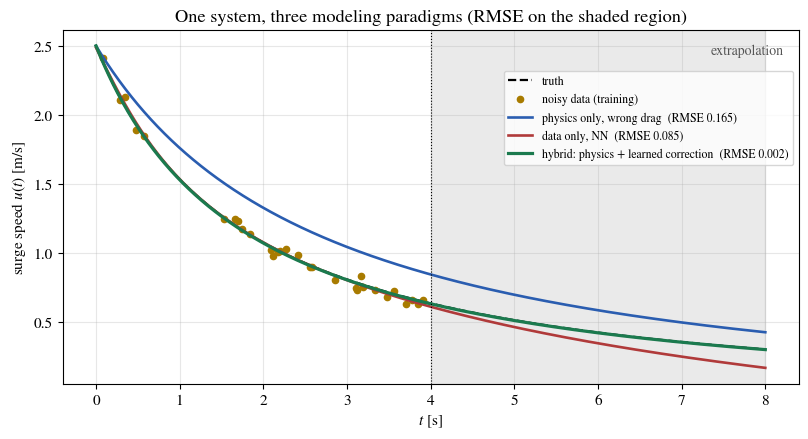

In [6]:
mask_ex = t_ref >= T_TRAIN
u_hyb_i = np.interp(t_ref, t_hyb, u_hyb)

def err(u, region):
    return np.sqrt(np.mean((u[region]-u_ref[region])**2))

rows = [("PBM (wrong drag)", u_pbm), ("DDM (network on data)", u_ddm),
        ("Hybrid (PBM + correction)", u_hyb_i)]
print(f"{'model':28s} {'in-dist RMSE':>14s} {'extrapolation RMSE':>20s}")
for name, u in rows:
    print(f"{name:28s} {err(u, ~mask_ex):14.4f} {err(u, mask_ex):20.4f}")

e_pbm, e_ddm, e_hyb = (err(u, mask_ex) for _, u in rows)
assert e_hyb < e_pbm/3, "the hybrid should beat its own imperfect physics"
assert e_hyb < e_ddm/3, "the hybrid should beat the pure network out of sample"

def plot_intro_three_paradigms():
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    ax.axvspan(T_TRAIN, T_END, color=muted(), alpha=0.12)
    ax.text(0.98, 0.96, 'extrapolation', transform=ax.transAxes, ha='right',
            va='top', fontsize=10, color=muted())
    ax.plot(t_ref, u_ref, color=fg(), ls='--', lw=1.6, label='truth')
    ax.plot(t_obs, u_obs, 'o', color='C5', ms=4.5, label='noisy data (training)')
    ax.plot(t_ref, u_pbm, color='C0', lw=1.9,
            label=f'physics only, wrong drag  (RMSE {e_pbm:.3f})')
    ax.plot(t_ref, u_ddm, color='C3', lw=1.9,
            label=f'data only, NN  (RMSE {e_ddm:.3f})')
    ax.plot(t_ref, u_hyb_i, color='C2', lw=2.3,
            label=f'hybrid: physics + learned correction  (RMSE {e_hyb:.3f})')
    ax.axvline(T_TRAIN, color=fg(), lw=0.8, ls=':')
    ax.set(xlabel='$t$ [s]', ylabel='surge speed $u(t)$ [m/s]',
           title='One system, three modeling paradigms (RMSE on the shaded region)')
    ax.legend(fontsize=8.5, loc='upper right', bbox_to_anchor=(1.0, 0.90))

save_dual(plot_intro_three_paradigms, 'intro_three_paradigms', FIG)
plt.show()

Read the table together with the figure. **In-distribution** ($t\le4$) all three are close — with
data everywhere even the black box looks fine. **Out of sample** ($t>4$, the shaded band) they
diverge: the physics-only curve (blue) rides above the truth by its fixed drag bias; the data-only
network (red) leaves the last data point and flattens into a meaningless extrapolation — the
*cliff*; the hybrid (green) tracks the dashed truth across the whole band because the physics
carries the structure and the one learned scalar supplies the missing drag. Both `assert`s pass, so
the hybrid's extrapolation RMSE is more than three times smaller than either pure approach. This
single figure is the argument for the entire course.

## What this course does with that figure

* The blue curve is Modules 1 (build the physics) and its honest limits.
* The red curve is Module 2 — powerful, and the extrapolation cliff is a
  theorem-grade warning, not an implementation bug.
* The green curve is where the course lives: physics carrying the
  structure, data fixing what the physics gets wrong — via the loss
  (Module 22), via operators (25–26), via corrections (20), via discovered
  equations (21), compressed to run in real time (5, 19).
* Every number above is asserted; every figure in the course is generated
  by a notebook like this one.